# Download ERA5 offshore waves at the goals

ERA5 ocean waves (ECMWF; hourly, 0.5°, 1940 onwards) from the Earth Data Hub
zarr, read only at the goal nodes and written in the HyWaves names on
`(time, goal)`, like any other offshore source:

- bulk `hs`, `tp`, `dir`, `spr`;
- partitions `phs{i}`, `ptp{i}`, `pdir{i}`, `pspr{i}`: 0 = wind sea, 1–3 = the
  three swell partitions.

ERA5 has no partition peak periods: it gives the partition **mean** periods
(Tm-1,0). *Partition peak periods* below converts them with the Tp / Tm-1,0
ratio measured on ERA5 itself, so the zarr holds peak periods like any other
source. The three swells share the total-swell spread.

**Key:** set the `EDH_API_KEY` environment variable (e.g. in `~/.bashrc`), or
type it when asked below. Never write it in the notebook.

**Prerequisites:** `04_Select_Goals_by_Hindcasts.ipynb` (the goals JSON, with
an `era5` node per goal) and an `ERA5` entry in `offshore_waves`.
**Next:** `07b_Satellite_Calibration.ipynb` with `offshore_name = "ERA5"`.

In [1]:
import getpass
import os

import matplotlib.pyplot as plt
import xarray as xr
from bluemath_tk.waves.hywaves.offshore import (
    EDH_KEY_VARIABLE,
    era5_at_goals,
    jonswap_tm10_ratio,
    open_era5_waves,
    partition_peak_periods,
    peak_period_samples,
)
from bluemath_tk.waves.hywaves.plots import plot_peak_period_ratio
from utils.config import get_offshore_wave, load_goals, resolve

## Configuration

In [2]:
offshore_name = "ERA5"  # offshore_waves entry this zarr feeds
period = slice("1979", "2023")  # time window (ERA5 starts in 1940)

out_path = resolve(get_offshore_wave(offshore_name)["data_path"])
if not os.environ.get(EDH_KEY_VARIABLE):
    os.environ[EDH_KEY_VARIABLE] = getpass.getpass("Earth Data Hub key: ")
print(f"output : {out_path}")
print(f"period : {period.start} – {period.stop}")

output : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/ERA5/processed/Netherlands_ERA5_goal.zarr
period : 1979 – 2023


## Goal nodes

The ERA5 node of each goal from the goals JSON (`hindcast.era5`, chosen in 04);
the nearest ERA5 grid point is read.

In [3]:
goals = load_goals()
nodes = {gid: goal["hindcast"][offshore_name.casefold()] for gid, goal in goals.items()}
goal_ids = [int(gid) for gid in nodes]
lon = [node["longitude"] for node in nodes.values()]
lat = [node["latitude"] for node in nodes.values()]
list(zip(goal_ids, lon, lat))

[(1, 2.5, 51.5),
 (2, 3.0, 52.0),
 (3, 3.5, 52.5),
 (4, 4.0, 53.0),
 (5, 4.5, 53.5),
 (6, 5.0, 54.0),
 (7, 5.5, 54.0),
 (8, 6.0, 54.0),
 (9, 6.5, 54.0),
 (10, 7.0, 54.0)]

## Download

All variables and partitions at the goal nodes (about a minute per decade).

In [4]:
era5 = era5_at_goals(open_era5_waves(), lon, lat, goal_ids, time=period)
era5

<xarray.Dataset> Size: 319MB
Dimensions:    (goal: 10, time: 394464)
Coordinates:
  * goal       (goal) int64 80B 1 2 3 4 5 6 7 8 9 10
    latitude   (goal) float64 80B 51.5 52.0 52.5 53.0 ... 54.0 54.0 54.0 54.0
    longitude  (goal) float64 80B 2.5 3.0 3.5 4.0 4.5 5.0 5.5 6.0 6.5 7.0
  * time       (time) datetime64[ns] 3MB 1979-01-01 ... 2023-12-31T23:00:00
Data variables: (12/20)
    hs         (time, goal) float32 16MB 2.428 2.355 2.393 ... 2.297 2.057 1.841
    tp         (time, goal) float32 16MB 8.242 8.07 9.539 ... 6.848 6.188 6.188
    dir        (time, goal) float32 16MB 42.41 41.22 37.66 ... 206.5 204.1 202.2
    spr        (time, goal) float32 16MB 28.12 29.07 28.0 ... 30.44 30.72 30.66
    phs0       (time, goal) float32 16MB 1.385 1.308 1.602 ... 2.143 1.873 1.664
    ptp0       (time, goal) float32 16MB 4.797 4.863 5.473 ... 5.73 5.344 5.008
    ...         ...
    phs3       (time, goal) float32 16MB 0.04907 0.02908 ... 0.04956 0.04956
    ptp3       (time, goal) float32 16MB 12.89 12.97 23.75 ... 4.711 4.145 4.145
    pdir3      (time, goal) float32 16MB 243.6 242.5 37.59 ... 59.03 10.93 10.93
    pspr1      (time, goal) float32 16MB 20.8 19.72 16.17 ... 22.4 18.88 17.19
    pspr2      (time, goal) float32 16MB 20.8 19.72 16.17 ... 22.4 18.88 17.19
    pspr3      (time, goal) float32 16MB 20.8 19.72 16.17 ... 22.4 18.88 17.19
Attributes:
    source:      ERA5 single levels, ocean waves (ECMWF), via Earth Data Hub
    url:         https://data.earthdatahub.destine.eu/era5/era5-single-levels...
    partitions:  0 = wind sea, 1-3 = swell partitions
    note:        ptp* are partition mean periods (Tm-1,0), not peak periods; ...

## Partition peak periods

The metamodel is forced with peak periods; ERA5 gives the partitions' mean
period Tm-1,0. For a JONSWAP spectrum Tp / Tm-1,0 is 1.17 (γ = 1,
Pierson-Moskowitz), 1.11 (γ = 3.3) and 1.07 (γ = 7, a narrow swell).

Measured on ERA5 itself: at the hours one partition holds at least 90 % of the
energy, the bulk peak period (`pp1d`) is that partition's peak, so
`tp / ptp{i}` is its ratio. The medians (wind sea, and the swells pooled)
convert `ptp{i}`. Netherlands 1979–2023, 10 goals: sea 1.156, swell 1.132
(the swells sit above a narrow JONSWAP: ERA5's swell partitions are broad).

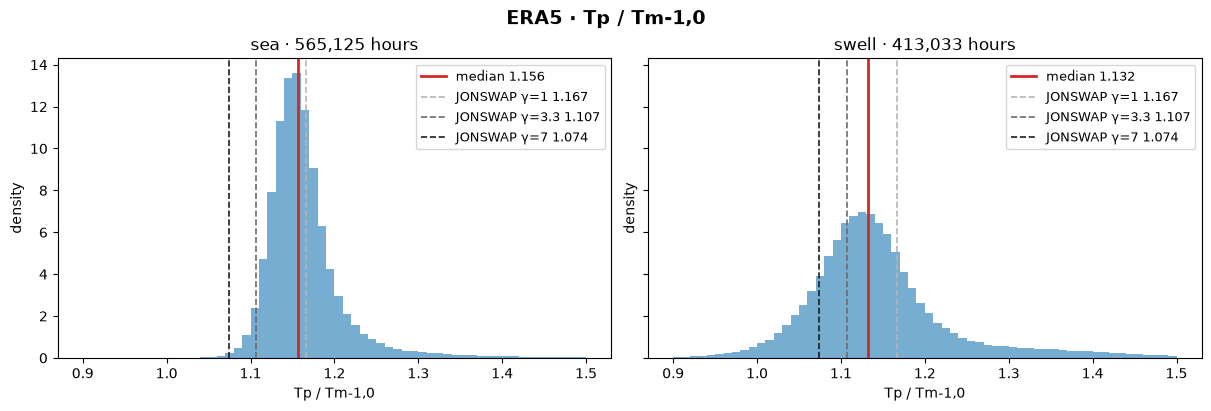

{'sea': 1.1560453176498413, 'swell': 1.132063865661621}

In [5]:
samples = peak_period_samples(era5, min_fraction=0.9)
ratios = samples.groupby("partition")["ratio"].median().to_dict()
theory = {f"JONSWAP γ={g:g}": 1 / jonswap_tm10_ratio(g) for g in (1.0, 3.3, 7.0)}
fig = plot_peak_period_ratio(samples, theory, title="ERA5 · Tp / Tm-1,0")
plt.show()
ratios

In [6]:
era5_tp = partition_peak_periods(era5, ratios)
era5_tp["ptp1"].attrs

{'long_name': 'Peak wave period (Tm-1,0 x 1.132), swell 1',
 'units': 's',
 'era5_name': 'mwp1',
 'tp_tm10_ratio': 1.132063865661621}

In [7]:
out_path.parent.mkdir(parents=True, exist_ok=True)
era5_tp.chunk({"time": -1, "goal": 1}).to_zarr(out_path, mode="w")
print(f"written {out_path}")

written /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/ERA5/processed/Netherlands_ERA5_goal.zarr


## Check

In [8]:
check = xr.open_zarr(out_path)
summary = check[["hs", "phs0", "phs1", "phs2", "phs3"]].mean("time").to_dataframe()
summary["missing_hs"] = check["hs"].isnull().mean("time").to_series()
summary.round(3)

,hs,phs0,phs1,phs2,phs3,latitude,longitude,missing_hs
goal,,,,,,,,
1,1.087,0.842,0.496,0.137,0.033,51.5,2.5,0.0
2,1.225,0.935,0.564,0.156,0.034,52.0,3.0,0.0
3,1.295,0.971,0.646,0.177,0.037,52.5,3.5,0.0
4,1.353,1.000,0.664,0.175,0.037,53.0,4.0,0.0
5,1.403,1.024,0.807,0.223,0.048,53.5,4.5,0.0
6,1.567,1.118,0.852,0.236,0.051,54.0,5.0,0.0
7,1.540,1.108,0.828,0.215,0.046,54.0,5.5,0.0
8,1.495,1.080,0.799,0.191,0.042,54.0,6.0,0.0
9,1.446,1.042,0.777,0.175,0.038,54.0,6.5,0.0
